## Project 1 - Linear Regression as a Classification Model

### Summary
Using real world data from actual user traffic to nike.com, determine if: page view for the website was on a desktop platform or a mobile device.

The following four performance based metrics are used to train the supervised model:

1. `Dom Processing Duration` - (seconds) time for the web browser to build the Document Object Model (typically when the page is ready to interact with )
2. `Page Rendering Duration` - (seconds) time after dom processing is complete until the page shows all visible content, images, text, vidoes
3. `Network Duration` - (seconds) time spent receiving initial document, considerably slower on slower connections, ie mobile 3g
4. `First Contentful Paint` - (seconds) time when the user first sees something on the page, this metric has a downstream dependency on the above 3 metrics

Knowing that, typically, desktop platforms have more available: cpu processing power, memory and typically internet bandwidth, compared to mobile devices - these metrics should describe the user's topology well.  There is variance though, some mobile devices are powerful enough to appear as a desktop device and corollary desktop platforms may have a slow connection/cpu and appear to preform closer to a mobile device.

To keep the dataset as clean as possible the data has been scoped to only users in the US and also focused on the same browser type across desktop and across mobile - which is the `Safari` browser.

In addition the nike.com page is a product display page of a popular product (url not listed here to keep data anonomous).  Using the same page helps to reduce variance amongst user visits

### Objective 
- Split the model into a training set and testing set

- Use One Hot Encoding to classify the output:
    - desktop: [1,0]
    - mobile: [0,1]

- Fit the linear regression model on the training set
- Provide analysis of results
- Fit a logistic regression model
- Provide analyis of how the regression model compares to the linear model


The main objective is to use data that shows no obvious outcoms (desktop or mobile) when viewed with the human eye. For example, attributes (features) such as: screen size, orientation, or OS name would provide a direct relationship to the outcome (dependent variable).   Here, we must rely on more subtle attributes and how the chosen metrics work together to give signals towards the dependent variable.  

Another point, is multicollinearity and how that affects our prediction model.  The metrics available can have a dependence on each other as they could typically happen in a certain order.  I don't think this is a problem for a prediction model.  Reason being, we are concerned with how all the metrics work together to predict an outcome vs how 1 metric in isolation can affect an outcome by a certain degree.




Data Retrieval

Data was pulled from a 3rd party vendor (New Relic) that is used to track user visits with their associated performance metrics and meta data.
It was queried within New Relics query UI and exported as a csv
1. 5000Desktop.csv
2. 5000Mobile.csv

With the amount of traffic on nike.com the query timeline was less than 1 day each of Desktop and Mobile

On initial data retrieval, fields with null values were excluded.

5000 records is a large dataset for this prediction model, though with the amount of variance or overlap in data my thinking is that more data will increase the accuracy of the prediction model

It would be interesting to run this model with less data to determine the minimum set of data with the same accuracy


In [79]:
# setup standard imports for data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns   
import statsmodels.api as sm

# modeling and evaluation
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report
from sklearn.preprocessing import StandardScaler

In [80]:

# drop any row that has at least one missing value
# note: the initial query from New Relic should have dealt with this
def clean_data(df):
    # drop rows with missing values
    initial_row_count = len(df)
    df = df.dropna()
    post_row_count = len(df)
    print(("preprocessing: removed {} rows with missing values").format(initial_row_count - post_row_count))
    
    return df


# on viewing of the scatter plot initially, we saw outliers that made all the bulk of the data compressed in the lower left corner
# removing outlier above the 99th percentile for each feature, this is a common method to remove outliers in a dataset
def remove_outliers(df):
    rows_before = len(df)
    for col in featureList:
        upper_bound = df[col].quantile(0.99)
        df = df[df[col] <= upper_bound]
    print(f"Dropped {rows_before - len(df)} rows above the 99th percentile cutoffs.")
    return df

- load data in data frames: read each csv file and combine into a single dataframe
- preprocess data, remove any rows with missing values


In [81]:
df_mobile = pd.read_csv("5000Mobile.csv")
df_desktop = pd.read_csv("5000Desktop.csv")

df = pd.concat([df_mobile, df_desktop], ignore_index=True)

# from the csv header, set the feature list and target variable
featureList = ["Dom Processing Duration", "Page Rendering Duration", "Network Duration", "First Contentful Paint"]
target = "Device Type"

df = clean_data(df)
df = remove_outliers(df)



preprocessing: removed 0 rows with missing values
Dropped 395 rows above the 99th percentile cutoffs.


One Hot Encode Output Labels

In [82]:
# Create one-hot encoding using np.eye, this will encode all the y values results in a 10,000 x 2 matrix

unique_values, indices = np.unique(df[target], return_inverse=True)
Y_ohe = np.eye(len(unique_values))[indices]
print("one-hot encoded labels shape: {}".format(Y_ohe.shape))
print(Y_ohe[:3]) 



one-hot encoded labels shape: (9605, 2)
[[0. 1.]
 [0. 1.]
 [0. 1.]]


Split dataframe into a training set and a testing set
we need some additional lists here:
X_train, X_test, Y_train, Y_test: are what we feed the models
y_train_idx, y_test_idx: are for our sanity checks and, later, the confusion matrix

In [83]:
class_names = sorted(df[target].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
y_indices = np.array([class_to_idx[label] for label in df[target]])

# split the data into training and testing sets
# for each list we pass in, we get back two lists: one for training and one for testing
# 20% of the data will be used for testing, and the rest for training
# 42 is the random seed for reproducibility (42 is typically used)
X_train, X_test, y_train, y_test, y_train_idx, y_test_idx = train_test_split(df[featureList], Y_ohe, y_indices, test_size=0.2, random_state=42)


print(f"Training set size: {len(X_train)}")
print(f"Testing set size:  {len(X_test)}")

Training set size: 7684
Testing set size:  1921


### Scatterplot visualization
The next step is to plot 2 features in a scatterplot, but the question is which 2 features from the 4 features do we pick?

There is a concept of a "Fisher's Score" where we find the difference in means then squared divided by the sum of the variances

Let's execute it and find the top 2 features

In [84]:
def get_best_two_features(X, y):
    f_ratios = []
    for i in range(X.shape[1]):  # Loop through all 4 features
        feature_data = X[:, i]
        # Separate the feature into the two classes (0 and 1), ie all the values of the feature for class 0 or 1
        class0 = feature_data[y == 0] 
        class1 = feature_data[y == 1]
        
        # Math: (Difference in Means)^2 / (Sum of Variances)
        numerator = (np.mean(class0) - np.mean(class1))**2
        denominator = np.var(class0) + np.var(class1)
        f_ratios.append(numerator / denominator)
    
    # Return the indices of the 2 features with the highest scores
    return np.argsort(f_ratios)[-2:]

# Usage
best_pair = get_best_two_features(X_train.values, y_train_idx)
print("feature names: {}".format([featureList[i] for i in best_pair]))

feature names: ['Page Rendering Duration', 'First Contentful Paint']


Now that we have our 2 best features, let's plot them on a scatter plot and see how the separation looks.
Since we have 4 features we can't visualize a 4D object, so this would be a 2D projection

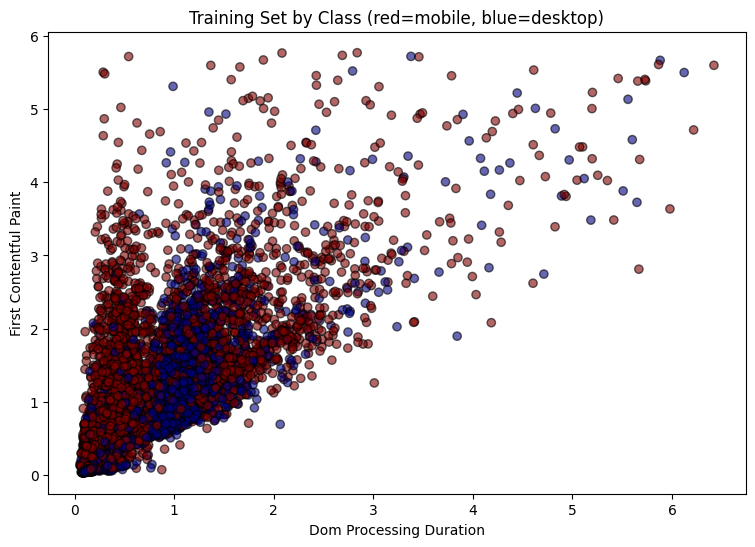

In [85]:
plot_x = "Dom Processing Duration"
plot_y = "First Contentful Paint"

plt.figure(figsize=(9, 6))
plt.scatter(
    X_train[plot_x],
    X_train[plot_y],
    c=y_train_idx,
    edgecolors='k',
    cmap=plt.cm.jet,
    alpha=0.6
)
plt.title("Training Set by Class (red=mobile, blue=desktop)")
plt.xlabel(plot_x)
plt.ylabel(plot_y)
plt.show()

The scatter plot shows substantial overlap, especially in the lower-left region, which suggests that when `First Contentful Paint` and `Dom Processing Duration` have low values, the classes are harder to distinguish. The confusion matrix should reflect this as missclassifications

Model Implementation

Comparision with Logistic Regression

plot_x = "Dom Processing Duration"
plot_y = "First Contentful Paint"

plt.figure(figsize=(9, 6))
plt.scatter(
    X_train[plot_x],
    X_train[plot_y],
    c=y_train_idx,
    edgecolors='k',
    cmap=plt.cm.jet,
    alpha=0.6
)
plt.title("Training Set by Class (2D Projection)")
plt.xlabel(plot_x)
plt.ylabel(plot_y)
plt.show()